# Toy Diffusion: BroyDEER vs Sequential DDIM

We treat DDIM sampling as a **forward-time dynamical system**
$$\text{state}[s+1] = f(\text{state}[s], \text{driver}[s])$$
where $\text{state}[s] = x_{T-s}$ — so $\text{state}[0]$ is pure noise and $\text{state}[T]$ is the clean image. The driver carries the per-step injected noise and the original DDIM timestep $t = T - s$.

The dynamics function calls a noise predictor $\varepsilon_\theta$, which here is the closed-form Bayes-optimal score for a **mixture of Gaussians** $\sum_k \pi_k\,\mathcal{N}(\mu_k, I)$ — a stand-in for a real diffusion U-Net that lets us validate BroyDEER integration on a known fixed point with a non-trivial (diagonal-plus-low-rank) Jacobian.

**Goal**: compare iterations to convergence of
- Sequential DDIM (reference)
- Picard / Jacobi / DEER / quasi-DEER
- Broyden-DEER
- Accelerated Broyden
- Full-Broyden (global Woodbury)

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import jax
import jax.numpy as jnp
import jax.random as jr
import numpy as np
import matplotlib.pyplot as plt

import sys, os
sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), "src"))

from algs.deer import deer_alg, picard_alg, jacobi_alg
from algs.broyden_deer import broyden_deer_alg
from algs.full_broyden import full_broyden_deer_alg
from algs.accelerated_broyden import accelerated_broyden_deer_alg
from algs.taa import taa_alg, taa_ddim_alg
from dynamics.diffusion import make_toy_diffusion_mog

# Mixture-of-Gaussians eps (nonlinear, breaks DEER ≡ quasi-DEER)

The single-Gaussian `ToyEps` is **linear in $x$**, so its Jacobian collapses to $J_s = c_s I_D$ — a scalar multiple of the identity. That makes DEER and quasi-DEER mathematically identical, since $\mathrm{diag}(c_s I) = c_s I$.

For a mixture $\sum_k \pi_k \mathcal{N}(\mu_k, I)$, the Bayes-optimal eps is still closed form,
$$\varepsilon^*(x_t, t) = \sqrt{1-\bar\alpha_t}\,\big(x_t - \sqrt{\bar\alpha_t}\,\bar\mu(x_t)\big),\qquad \bar\mu(x_t) = \sum_k w_k(x_t)\,\mu_k,$$
with soft assignments $w_k \propto \pi_k\exp(-\tfrac12\|x_t - \sqrt{\bar\alpha_t}\mu_k\|^2)$. The Jacobian becomes **diagonal-plus-low-rank**:
$$J_s \;=\; c_s\,I_D \;-\; \beta_s\,\Sigma_w(x_t),\qquad \Sigma_w(x_t) = \textstyle\sum_k w_k\,\mu_k\mu_k^\top - \bar\mu\bar\mu^\top,$$
with $\mathrm{rank}(\Sigma_w) \le K-1$ and state-dependent. This is exactly the structure Broyden-class methods are designed to exploit, and quasi-DEER pays a real penalty for dropping the off-diagonals of $\Sigma_w$.

In [3]:
# Smaller D and tiny cluster_scale so soft assignments are non-trivial at
# intermediate timesteps: cluster separation ||mu_j - mu_k||^2 ~ 2*sigma^2*D
# vs noise scale 1, so the log-discriminator alpha_bar_t * D * sigma^2 stays
# O(1) when sigma^2 ~ 1/(alpha_bar_t * D). For D=64, sigma=0.3 puts the
# transition in the middle of the schedule.
D_mog = 512
T_mog = 50
K_mog = 4

mog_deer_fxn, mog_dynamics, mog_x0, mog_drivers, mog_params = make_toy_diffusion_mog(
    D=D_mog, T=T_mog, K=K_mog, eta=0.0, cluster_scale=0.3, seed=42,
)
mog_alpha_bar = mog_params["alpha_bar"]
mog_mus       = mog_params["mus"]
mog_pis       = mog_params["pis"]

print(f"D = {D_mog}, T = {T_mog}, K = {K_mog} clusters")
print(f"||x0|| = {jnp.linalg.norm(mog_x0):.3f}")
for k in range(K_mog):
    print(f"  ||mu_{k}|| = {jnp.linalg.norm(mog_mus[k]):.3f}, pi_{k} = {mog_pis[k]:.3f}")
print(f"mean inter-cluster distance: "
      f"{float(jnp.mean(jnp.linalg.norm(mog_mus[:, None] - mog_mus[None, :], axis=-1))):.3f}")

D = 512, T = 50, K = 4 clusters
||x0|| = 23.019
  ||mu_0|| = 6.582, pi_0 = 0.250
  ||mu_1|| = 6.681, pi_1 = 0.250
  ||mu_2|| = 7.049, pi_2 = 0.250
  ||mu_3|| = 6.765, pi_3 = 0.250
mean inter-cluster distance: 7.287


In [4]:
mog_scan_fxn = mog_params["scan_fxn"]

@jax.jit
def run_mog_seq(x0, drivers):
    _, traj = jax.lax.scan(mog_scan_fxn, x0, drivers)
    return traj

mog_traj_seq = run_mog_seq(mog_x0, mog_drivers)
print(f"trajectory shape: {mog_traj_seq.shape}  (T latents)")
print(f"||x_T (final sample)|| = {jnp.linalg.norm(mog_traj_seq[-1]):.3f}")

# Which cluster did the final sample land near?
final_dists = jnp.linalg.norm(mog_traj_seq[-1][None, :] - mog_mus, axis=1)
print(f"distances from final sample to each cluster mean: {np.array(final_dists).round(3)}")
print(f"closest cluster: {int(jnp.argmin(final_dists))}")

trajectory shape: (50, 512)  (T latents)
||x_T (final sample)|| = 22.967
distances from final sample to each cluster mean: [24.203 24.302 24.362 22.757]
closest cluster: 3


In [5]:
mog_x0_deer = mog_x0
mog_guess   = jnp.broadcast_to(mog_x0, (T_mog, D_mog))
mog_max_n   = 100
mog_iters   = list(range(1, mog_max_n + 1))

*_, mog_deer_errs   = deer_alg(mog_deer_fxn, mog_x0_deer, mog_guess, mog_drivers, mog_max_n, full_trace=True)
*_, mog_quasi_errs  = deer_alg(mog_deer_fxn, mog_x0_deer, mog_guess, mog_drivers, mog_max_n, quasi=True, full_trace=True)
*_, mog_jacobi_errs = deer_alg(mog_deer_fxn, mog_x0_deer, mog_guess, mog_drivers, mog_max_n, k=1, full_trace=True)
*_, mog_picard_errs = picard_alg(mog_deer_fxn, mog_x0_deer, mog_guess, mog_drivers, mog_max_n, full_trace=True)

mog_deer_errs   = list(np.array(mog_deer_errs))
mog_quasi_errs  = list(np.array(mog_quasi_errs))
mog_jacobi_errs = list(np.array(mog_jacobi_errs))
mog_picard_errs = list(np.array(mog_picard_errs))

In [6]:
# Sanity check: DEER's converged solution should match sequential DDIM exactly
_, mog_deer_final, *_ = deer_alg(
    mog_deer_fxn, mog_x0_deer, mog_guess, mog_drivers, num_iters=mog_max_n, tol=1e-10
)
max_err = jnp.max(jnp.abs(mog_deer_final - mog_traj_seq))
print(f"max |deer_final - sequential| = {max_err:.2e}")

max |deer_final - sequential| = 2.60e-05


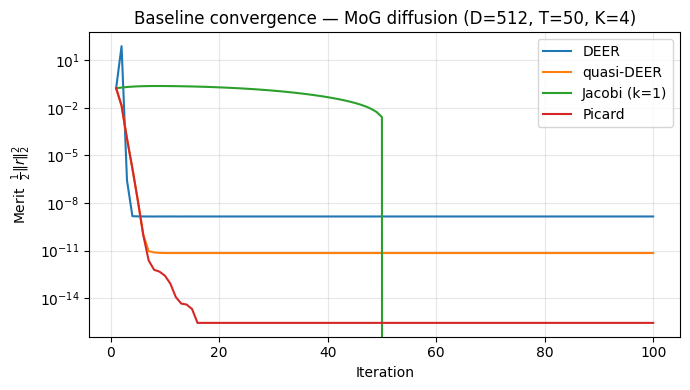

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(mog_iters, mog_deer_errs,   label="DEER")
ax.semilogy(mog_iters, mog_quasi_errs,  label="quasi-DEER")
ax.semilogy(mog_iters, mog_jacobi_errs, label="Jacobi (k=1)")
ax.semilogy(mog_iters, mog_picard_errs, label="Picard")
ax.set_xlabel("Iteration")
ax.set_ylabel(r"Merit  $\frac{1}{2}\|r\|_2^2$")
ax.set_title(f"Baseline convergence — MoG diffusion (D={D_mog}, T={T_mog}, K={K_mog})")
ax.legend(); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()

## Broyden-DEER

Local rank-$m$ secant blocks per timestep. Since $\Sigma_w(x_t)$ has rank at most $K-1$, $m = K-1$ should in principle suffice to capture the full Jacobian correction.

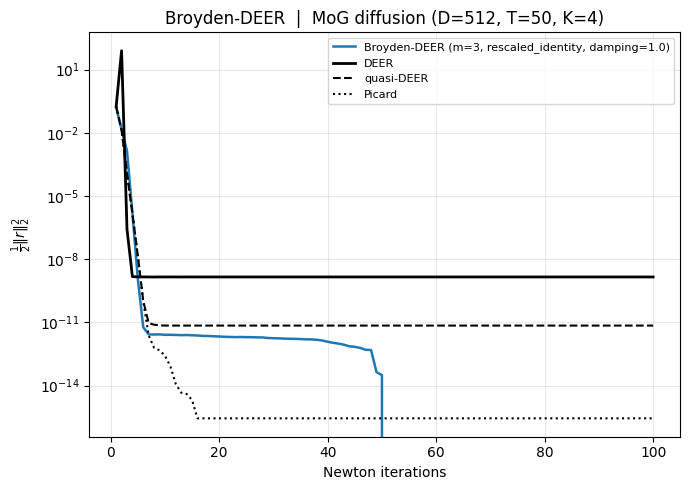

In [8]:
mog_bd_m       = K_mog - 1
mog_bd_init    = "rescaled_identity"
mog_bd_k = 0.0

*_, mog_bd_errs = broyden_deer_alg(
    mog_deer_fxn, mog_x0_deer, mog_guess, mog_drivers, mog_max_n,
    m=mog_bd_m, init=mog_bd_init, k=mog_bd_k, full_trace=True,
)
mog_bd_errs = list(np.array(mog_bd_errs))

fig, ax = plt.subplots(figsize=(7, 5))
ax.semilogy(mog_iters, mog_bd_errs, "-", color="tab:blue", linewidth=1.8,
            label=f"Broyden-DEER (m={mog_bd_m}, {mog_bd_init}, k={mog_bd_k})")
ax.semilogy(mog_iters, mog_deer_errs,   "k-",  linewidth=2,   label="DEER")
ax.semilogy(mog_iters, mog_quasi_errs,  "k--", linewidth=1.5, label="quasi-DEER")
ax.semilogy(mog_iters, mog_picard_errs, "k:",  linewidth=1.5, label="Picard")
ax.set_xlabel("Newton iterations")
ax.set_ylabel(r"$\frac{1}{2}\|r\|_2^2$")
ax.set_title(f"Broyden-DEER  |  MoG diffusion (D={D_mog}, T={T_mog}, K={K_mog})")
ax.legend(fontsize=8); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()

## Accelerated Broyden

Per-timestep diagonal Jacobian + sliding window of $k$ secant pairs.

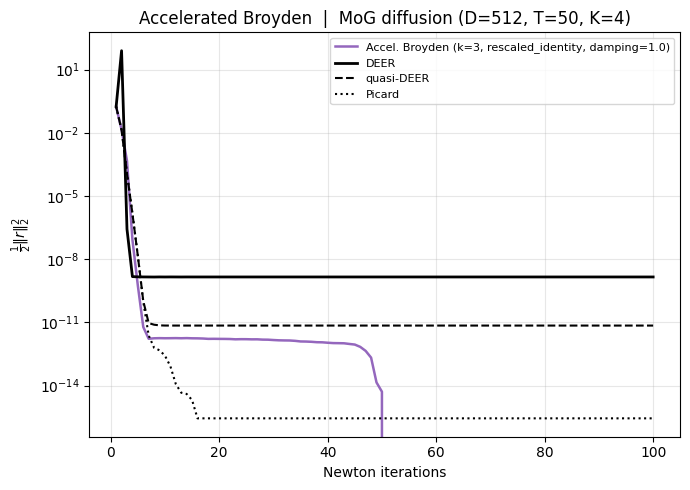

In [9]:
mog_acc_m        = K_mog - 1
mog_acc_init     = "rescaled_identity"
mog_acc_k  = 0.0
mog_acc_eps_gram = 1e-6

*_, mog_acc_errs = accelerated_broyden_deer_alg(
    mog_deer_fxn, mog_x0_deer, mog_guess, mog_drivers, mog_max_n,
    m=mog_acc_m, init=mog_acc_init, k=mog_acc_k,
    eps_gram=mog_acc_eps_gram, full_trace=True,
)
mog_acc_errs = list(np.array(mog_acc_errs))

fig, ax = plt.subplots(figsize=(7, 5))
ax.semilogy(mog_iters, mog_acc_errs, "-", color="tab:purple", linewidth=1.8,
            label=f"Accel. Broyden (m={mog_acc_m}, {mog_acc_init}, k={mog_acc_k})")
ax.semilogy(mog_iters, mog_deer_errs,   "k-",  linewidth=2,   label="DEER")
ax.semilogy(mog_iters, mog_quasi_errs,  "k--", linewidth=1.5, label="quasi-DEER")
ax.semilogy(mog_iters, mog_picard_errs, "k:",  linewidth=1.5, label="Picard")
ax.set_xlabel("Newton iterations")
ax.set_ylabel(r"$rac{1}{2}\|r\|_2^2$")
ax.set_title(f"Accelerated Broyden  |  MoG diffusion (D={D_mog}, T={T_mog}, K={K_mog})")
ax.legend(fontsize=8); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()

## Full-Broyden (global Woodbury)

Single global rank-$k$ update over the flattened $TD$ trajectory.

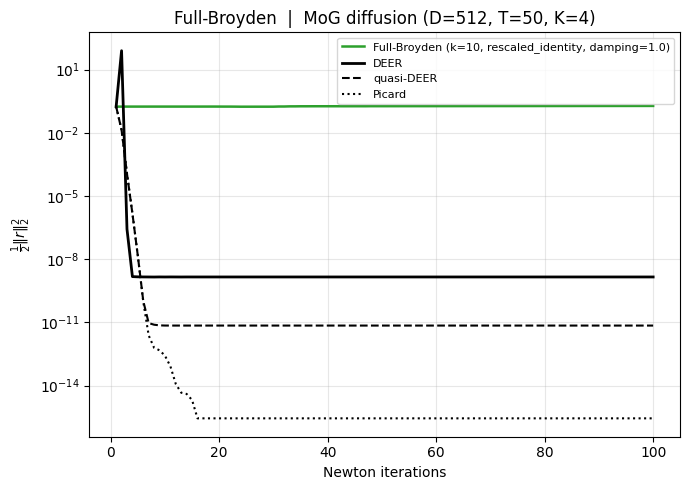

In [10]:
mog_fb_k       = 10
mog_fb_init    = "rescaled_identity"
mog_fb_damping = 1.0

*_, mog_fb_errs = full_broyden_deer_alg(
    mog_deer_fxn, mog_x0_deer, mog_guess, mog_drivers, mog_max_n,
    k=mog_fb_k, init=mog_fb_init, damping=mog_fb_damping, full_trace=True,
)
mog_fb_errs = list(np.array(mog_fb_errs))

fig, ax = plt.subplots(figsize=(7, 5))
ax.semilogy(mog_iters, mog_fb_errs, "-", color="tab:green", linewidth=1.8,
            label=f"Full-Broyden (k={mog_fb_k}, {mog_fb_init}, damping={mog_fb_damping})")
ax.semilogy(mog_iters, mog_deer_errs,   "k-",  linewidth=2,   label="DEER")
ax.semilogy(mog_iters, mog_quasi_errs,  "k--", linewidth=1.5, label="quasi-DEER")
ax.semilogy(mog_iters, mog_picard_errs, "k:",  linewidth=1.5, label="Picard")
ax.set_xlabel("Newton iterations")
ax.set_ylabel(r"$\frac{1}{2}\|r\|_2^2$")
ax.set_title(f"Full-Broyden  |  MoG diffusion (D={D_mog}, T={T_mog}, K={K_mog})")
ax.legend(fontsize=8); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()

## Triangular Anderson Acceleration (TAA)

ParaTAA's algorithm, ported to BroyDEER's API. At each iteration, we compute the per-timestep Picard residual $r_t = f(x_{t-1}, u_t) - x_t$, push it into a sliding memory of length `memory_size`, and solve **per-timestep** Anderson normal equations whose Gram matrix is built by **triangular cumulation** over time:
$$B_{ij}(t) \;=\; \sum_{t' \ge t}\; \langle dR_i(t'),\, dR_j(t') \rangle, \qquad d_i(t) = \sum_{t' \ge t} \langle dR_i(t'),\, r(t') \rangle$$
This pools error information from all *later* (more refined) timesteps to drive corrections at *earlier* ones — a natural fit for the strictly causal DDIM forward sweep. The update is
$$x_t^{\text{new}} \;=\; x_t \;+\; r_t \;-\; \sum_i c_t^{(i)}\,(dS_i(t) + dR_i(t)),\qquad c_t = (B(t) + \lambda I)^{-1} d(t).$$
Setting `memory_size = 1` recovers naive Picard. Note: ParaTAA's "higher-order residual" (multi-step lookahead) is DDIM-specific — it requires linearity of the dynamics in $\varepsilon$, so we omit it for the generic API.

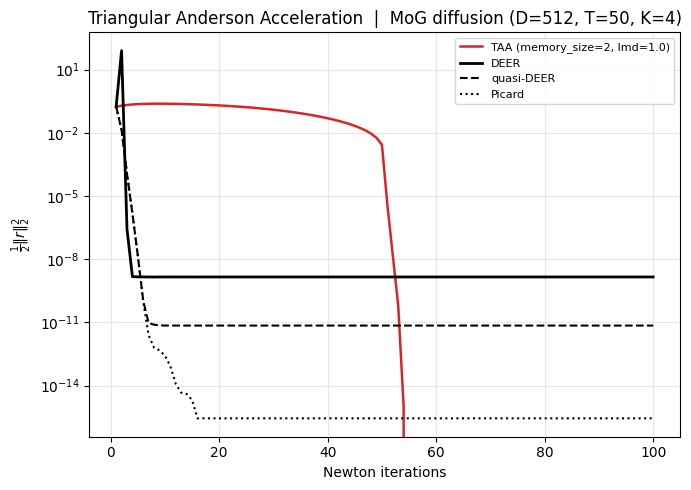

In [11]:
mog_taa_m   = 2
mog_taa_lmd = 1.0  # ParaTAA's default lmd=1e-3 was tuned for SD latents;
                   # at D=512 here the residual norms are larger, so a larger
                   # Tikhonov is needed to keep the Anderson solve stable.

*_, mog_taa_errs = taa_alg(
    mog_deer_fxn, mog_x0_deer, mog_guess, mog_drivers, mog_max_n,
    memory_size=mog_taa_m, lmd=mog_taa_lmd, full_trace=True,
)
mog_taa_errs = list(np.array(mog_taa_errs))

fig, ax = plt.subplots(figsize=(7, 5))
ax.semilogy(mog_iters, mog_taa_errs, "-", color="tab:red", linewidth=1.8,
            label=f"TAA (memory_size={mog_taa_m}, lmd={mog_taa_lmd})")
ax.semilogy(mog_iters, mog_deer_errs,   "k-",  linewidth=2,   label="DEER")
ax.semilogy(mog_iters, mog_quasi_errs,  "k--", linewidth=1.5, label="quasi-DEER")
ax.semilogy(mog_iters, mog_picard_errs, "k:",  linewidth=1.5, label="Picard")
ax.set_xlabel("Newton iterations")
ax.set_ylabel(r"$\frac{1}{2}\|r\|_2^2$")
ax.set_title(f"Triangular Anderson Acceleration  |  MoG diffusion (D={D_mog}, T={T_mog}, K={K_mog})")
ax.legend(fontsize=8); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()

### TAA with multi-step lookahead (`order` knob)

ParaTAA's third hyperparameter: `order = K` unrolls $K$ DDIM steps into a closed-form linear combination of $K$ eps evaluations on the *current* iterate, exploiting the fact that the DDIM update is linear in the noise direction. Since each eps eval is paid for once per outer step regardless, `order > 1` is essentially free.

BroyDEER index convention: with $X_s = x_{T-s}$, $a_s = c_x[T{-}s]$, $b_s = c_\varepsilon[T{-}s]$, $n_s = c_z[T{-}s]$, and $r_s = \max(0, s{+}1{-}K)$,
$$X_{s+1} \;=\; \Big(\!\prod_{k=r_s}^{s} a_k\!\Big)\, X_{r_s}\;+\;\sum_{j=r_s}^{s}\Big(\!\prod_{k=j+1}^{s}a_k\!\Big)\big(b_j\,\varepsilon_j + n_j\,z_j\big).$$

At `order=1` this collapses to single-step Picard and `taa_ddim_alg` reproduces `taa_alg` exactly.

max |taa_ddim(order=1) - taa_alg|  =  2.31e-07


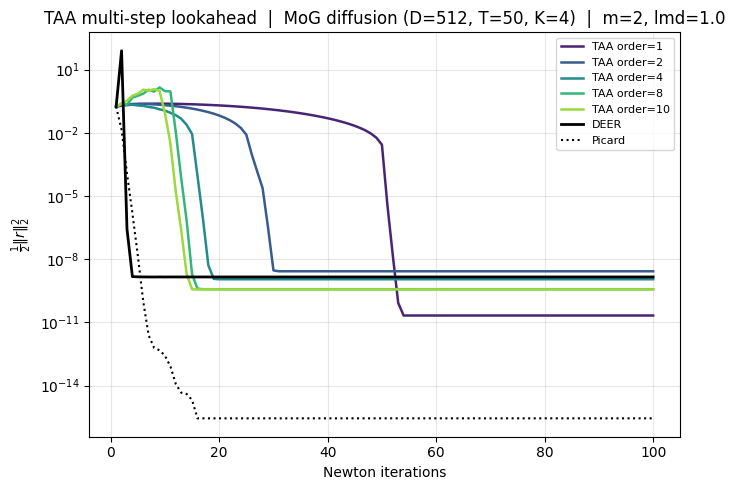

In [12]:
# head-to-head: TAA order=1 (== plain TAA)  vs  TAA order=K (multi-step lookahead)
mog_taa_m   = 2
mog_taa_orders = [1, 2, 4, 8, 10]
mog_taa_ord_errs = {}

for K in mog_taa_orders:
    *_, errs = taa_ddim_alg(
        mog_dynamics, mog_x0_deer, mog_guess, mog_drivers, mog_max_n,
        order=K, memory_size=mog_taa_m, lmd=mog_taa_lmd, full_trace=True,
    )
    mog_taa_ord_errs[K] = list(np.array(errs))

# sanity: order=1 should match plain taa_alg to numerical precision
_diff = float(np.max(np.abs(
    np.array(mog_taa_ord_errs[1]) - np.array(mog_taa_errs)
)))
print(f'max |taa_ddim(order=1) - taa_alg|  =  {_diff:.2e}')

fig, ax = plt.subplots(figsize=(7, 5))
_cmap = plt.cm.viridis(np.linspace(0.1, 0.85, len(mog_taa_orders)))
for color, K in zip(_cmap, mog_taa_orders):
    ax.semilogy(mog_iters, mog_taa_ord_errs[K], '-', color=color,
                linewidth=1.8, label=f'TAA order={K}')
ax.semilogy(mog_iters, mog_deer_errs,   'k-',  linewidth=2,   label='DEER')
ax.semilogy(mog_iters, mog_picard_errs, 'k:',  linewidth=1.5, label='Picard')
ax.set_xlabel('Newton iterations')
ax.set_ylabel(r'$\frac{1}{2}\|r\|_2^2$')
ax.set_title(f'TAA multi-step lookahead  |  MoG diffusion (D={D_mog}, T={T_mog}, K={K_mog})  |  m={mog_taa_m}, lmd={mog_taa_lmd}')
ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()

### TAA with sliding window (`window_size` knob)

ParaTAA's third axis: instead of updating all $T$ trajectory positions every outer iteration, maintain a *window* $[\,\text{front},\, \text{front}+W\,)$ of size $W$ and only refine inside it. The `front` advances past leading positions whose per-position residual has dropped below ParaTAA's two-tolerance criterion, freezing them at their settled value. With `order > 1` lookahead, Anderson can drive multiple positions through the window per outer iteration, and the front sweep skips ahead by more than 1 — that's the mechanism ParaTAA uses to break the $T$-iteration causality bound on DDIM.

Freeze criterion (matches `parallel_sd.py` exactly): position $s$ is frozen iff
$$\sqrt{\tfrac{1}{D}\|r_s\|_2^2} \;\le\; \texttt{wtol}_1
\quad\text{or}\quad
\sqrt{\tfrac{1}{D}\|r_s\|_2^2} \;\le\; \texttt{wtol}_2 \cdot \texttt{noise\_thr}_t$$
where $\texttt{noise\_thr}_t = \sqrt{(1-\bar\alpha_{t-1})/(1-\bar\alpha_t)} \cdot \sqrt{1 - \bar\alpha_t/\bar\alpha_{t-1}}$ is the eta-free natural DDIM noise scale. ParaTAA's defaults are $\texttt{wtol}_1 = 10^{-2}$ and $\texttt{wtol}_2 = 5\!\cdot\!10^{-2}$. When the front advances, newly-activated positions are warm-started from the just-settled adjacent position (`new_states[front + W - 1]`), again matching ParaTAA's `initialize_samples` trick.

Note: `window_size = T` does **not** reproduce the no-window run iter-by-iter, even at tight `wtol`. Position $s = 0$'s $K$-step lookahead anchor is the fixed `initial_state`, so its residual is exactly zero after iter 0; the front then advances at iter 1, after which the front-clipped K-band formula `ref_idx_clip = max(s+1-K, front)` no longer reaches back to the original anchor and the two trajectories take different (but equally valid) paths to the same fixed point.

first-iter (iter 0) max |window=T - no-window| residual diff:
  iter 0:  0.00e+00   iter 1:  0.00e+00


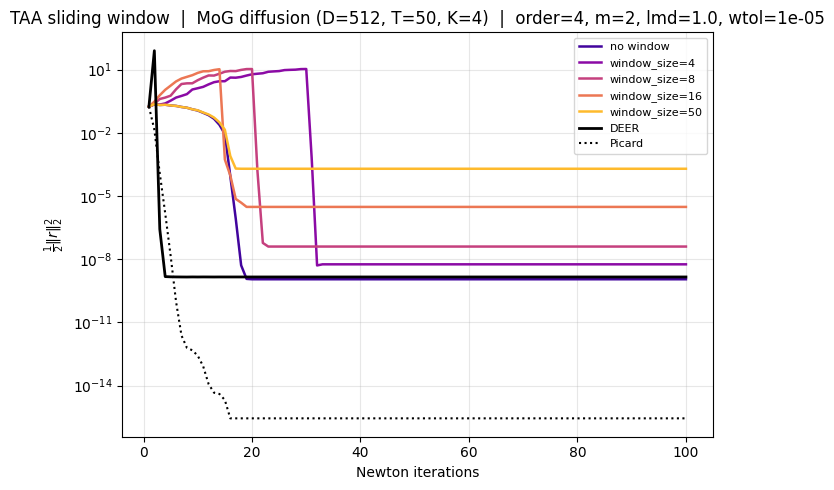

In [13]:
# window_size sweep at fixed (order, memory_size, lmd)
mog_taa_win_order = 4
mog_taa_win_m     = mog_taa_m
mog_taa_win_lmd   = mog_taa_lmd
mog_taa_win_sizes = [None, 4, 8, 16, T_mog]

# Tight wtol so positions only freeze once their per-coord RMS residual is
# well below the global merit tolerance. ParaTAA's defaults (1e-2 / 5e-2)
# trade per-position residual quality for fewer outer iterations and would
# plateau the merit curve well above the no-window run.
mog_taa_win_wtol = 1e-5

mog_taa_win_errs = {}
for W in mog_taa_win_sizes:
    *_, errs = taa_ddim_alg(
        mog_dynamics, mog_x0_deer, mog_guess, mog_drivers, mog_max_n,
        order=mog_taa_win_order,
        memory_size=mog_taa_win_m,
        lmd=mog_taa_win_lmd,
        window_size=W,
        window_tol1=mog_taa_win_wtol,
        window_tol2=mog_taa_win_wtol,
        full_trace=True,
    )
    mog_taa_win_errs[W] = list(np.array(errs))

# Note: window_size=T does NOT track the no-window run iter-by-iter, even
# with tight wtol. Position s=0's K-step lookahead anchor is `initial_state`
# (a fixed point), so it converges in iter 0; the front then advances at
# iter 1 and from iter 2 onward the front-clipped K-step formula
# (`ref_idx_clip = max(s + 1 - K, front)`) differs from the unclipped
# no-window version. The two trajectories follow different (but each
# correct-to-the-same-fixed-point) paths.
print(f'first-iter (iter 0) max |window=T - no-window| residual diff:')
_d0 = float(np.abs(np.array(mog_taa_win_errs[T_mog])[0] -
                   np.array(mog_taa_win_errs[None])[0]))
_d1 = float(np.abs(np.array(mog_taa_win_errs[T_mog])[1] -
                   np.array(mog_taa_win_errs[None])[1]))
print(f'  iter 0:  {_d0:.2e}   iter 1:  {_d1:.2e}')

fig, ax = plt.subplots(figsize=(7, 5))
_cmap = plt.cm.plasma(np.linspace(0.1, 0.85, len(mog_taa_win_sizes)))
for color, W in zip(_cmap, mog_taa_win_sizes):
    label = 'no window' if W is None else f'window_size={W}'
    ax.semilogy(mog_iters, mog_taa_win_errs[W], '-', color=color,
                linewidth=1.8, label=label)
ax.semilogy(mog_iters, mog_deer_errs,   'k-', linewidth=2,   label='DEER')
ax.semilogy(mog_iters, mog_picard_errs, 'k:', linewidth=1.5, label='Picard')
ax.set_xlabel('Newton iterations')
ax.set_ylabel(r'$\frac{1}{2}\|r\|_2^2$')
ax.set_title(
    f'TAA sliding window  |  MoG diffusion (D={D_mog}, T={T_mog}, K={K_mog})'
    f'  |  order={mog_taa_win_order}, m={mog_taa_win_m}, lmd={mog_taa_win_lmd}, wtol={mog_taa_win_wtol}'
)
ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()

## All methods on one plot

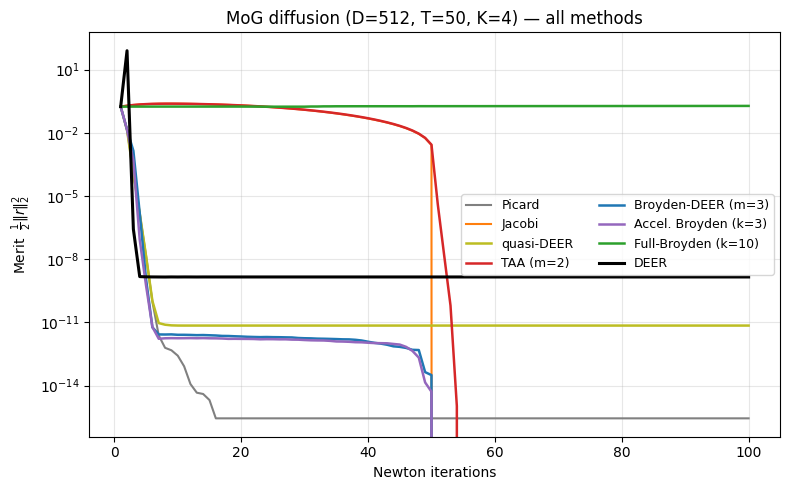

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))

_series = [
    ("mog_picard_errs", "Picard",                       "gray",       1.5, "-"),
    ("mog_jacobi_errs", "Jacobi",                       "tab:orange", 1.5, "-"),
    ("mog_quasi_errs",  "quasi-DEER",                   "tab:olive",  1.8, "-"),
    ("mog_taa_errs",    f"TAA (m={locals().get('mog_taa_m', '?')})",
                                                        "tab:red",    1.8, "-"),
    ("mog_bd_errs",     f"Broyden-DEER (m={K_mog-1})",  "tab:blue",   1.8, "-"),
    ("mog_acc_errs",    f"Accel. Broyden (k={K_mog-1})","tab:purple", 1.8, "-"),
    ("mog_fb_errs",     "Full-Broyden (k=10)",          "tab:green",  1.8, "-"),
    ("mog_deer_errs",   "DEER",                         "k",          2.2, "-"),
]
for name, label, color, lw, ls in _series:
    if name in locals():
        ax.semilogy(mog_iters, locals()[name], ls, color=color, linewidth=lw, label=label)

ax.set_xlabel("Newton iterations")
ax.set_ylabel(r"Merit  $\frac{1}{2}\|r\|_2^2$")
ax.set_title(f"MoG diffusion (D={D_mog}, T={T_mog}, K={K_mog}) — all methods")
ax.legend(fontsize=9, ncol=2); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()

# Real DiT-XL/2 Experiment (CPU, T=10)

Run DEER, Picard, and TAA on the **pretrained DiT-XL/2** (256×256, ImageNet class 207 = golden retriever).
With T=10 DDIM steps and ~3 s per eps call on CPU, expect ~5 min total.

In [ ]:
import time
from models.dit import make_dit_diffusion, load_vae, decode_latent

dit_ckpt = "../pretrained_models/DiT-XL-2-256x256.pt"
dit_T = 10
dit_class = 207   # golden retriever
dit_cfg   = 4.0
dit_max_n = 10    # Newton iterations

print(f"Building DiT-XL/2 dynamics (T={dit_T}) ...")
t0 = time.time()
dit_deer_fxn, dit_dynamics, dit_x0, dit_drivers, dit_params = make_dit_diffusion(
    dit_ckpt, T=dit_T, class_label=dit_class, cfg_scale=dit_cfg, eta=0.0, seed=0,
)
print(f"Done in {time.time()-t0:.1f}s")

dit_D = dit_x0.shape[0]
dit_guess = jnp.broadcast_to(dit_x0, (dit_T, dit_D))
dit_iters = list(range(1, dit_max_n + 1))
print(f"D={dit_D}, T={dit_T}, max_n={dit_max_n}")

Building DiT-XL/2 dynamics (T=10) ...
Done in 12.4s
D=4096, T=10, max_n=10


: 

In [ ]:
print(f"Running DEER (T={dit_T}, {dit_max_n} iters) ...")
t0 = time.time()
*_, dit_deer_sol, _, dit_deer_errs = deer_alg(
    dit_deer_fxn, dit_x0, dit_guess, dit_drivers, dit_max_n, full_trace=True,
)
dit_deer_errs = list(np.array(dit_deer_errs))
print(f"DEER done in {time.time()-t0:.1f}s")
print(f"  final merit = {dit_deer_errs[-1]:.4e}")

Running DEER (T=10, 10 iters) ...


In [ ]:
print(f"Running Picard (T={dit_T}, {dit_max_n} iters) ...")
t0 = time.time()
*_, dit_picard_sol, _, dit_picard_errs = picard_alg(
    dit_deer_fxn, dit_x0, dit_guess, dit_drivers, dit_max_n, full_trace=True,
)
dit_picard_errs = list(np.array(dit_picard_errs))
print(f"Picard done in {time.time()-t0:.1f}s")
print(f"  final merit = {dit_picard_errs[-1]:.4e}")

In [ ]:
print(f"Running TAA (T={dit_T}, {dit_max_n} iters, order=4, m=2) ...")
t0 = time.time()
*_, dit_taa_sol, _, dit_taa_errs = taa_ddim_alg(
    dit_dynamics, dit_x0, dit_guess, dit_drivers, dit_max_n,
    order=4, memory_size=2, lmd=1e-3,
    full_trace=True,
)
dit_taa_errs = list(np.array(dit_taa_errs))
print(f"TAA done in {time.time()-t0:.1f}s")
print(f"  final merit = {dit_taa_errs[-1]:.4e}")

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(dit_iters, dit_picard_errs, 'o-',  color='gray',      linewidth=1.5, label='Picard')
ax.semilogy(dit_iters, dit_deer_errs,   's-',  color='k',         linewidth=2,   label='DEER')
ax.semilogy(dit_iters, dit_taa_errs,    '^-',  color='tab:red',   linewidth=1.8, label='TAA (order=4, m=2)')
ax.set_xlabel('Newton iterations')
ax.set_ylabel(r'Merit  $\frac{1}{2}\|r\|_2^2$')
ax.set_title(f'DiT-XL/2  (T={dit_T}, class={dit_class}, cfg={dit_cfg})')
ax.legend(fontsize=9)
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()

## Decode final latents to images via VAE

In [ ]:
print("Loading VAE ...")
vae = load_vae(device="cpu")
print("VAE loaded.")

C, H, W = dit_params["latent_shape"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (sol, name) in zip(axes, [
    (dit_deer_sol,   "DEER"),
    (dit_picard_sol, "Picard"),
    (dit_taa_sol,    "TAA"),
]):
    # sol is (T, D) — take the last row (final denoised state)
    latent = sol[-1].reshape(C, H, W)
    img = decode_latent(vae, latent)
    ax.imshow(img)
    ax.set_title(f"{name}  ({img.shape[0]}×{img.shape[1]})", fontsize=12)
    ax.axis('off')

fig.suptitle(f'DiT-XL/2  |  class {dit_class} (golden retriever)  |  T={dit_T}, cfg={dit_cfg}',
             fontsize=13, y=1.02)
plt.tight_layout()